In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/2026task1/submission-for-task2.csv
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/lzxpeiohkd.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/xonkpltokc.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/egpzdxqvpd.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/xwgxsdrayz.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/rojhnoqhlm.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/skvswklmwr.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/kmdvdjjrja.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/esqiikafkg.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/urwemzusdg.png
/kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/ulzmjrmejy.png
/kaggle/

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

In [3]:
from pathlib import Path
import pandas as pd

# 数据路径
DATA_ROOT = Path(
    "/kaggle/input/competitions/2026task1/"
    "dataset-for-task2/dataset-for-task2"
)

TRAIN_ROOT = DATA_ROOT / "train"
TEST_ROOT = DATA_ROOT / "test"

# 类别名称
class_names = sorted([
    p.name for p in TRAIN_ROOT.iterdir()
    if p.is_dir()
])

print("类别：")
for i, name in enumerate(class_names):
    print(i, "->", name)

类别：
0 -> Black-grass
1 -> Common wheat
2 -> Loose Silky-bent
3 -> Scentless Mayweed
4 -> Sugar beet


In [4]:
train_data = []

for label, class_name in enumerate(class_names):

    class_dir = TRAIN_ROOT / class_name

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            train_data.append({
                "path": str(image_path),
                "label": label
            })

train_df = pd.DataFrame(train_data)

print("训练图片数量：", len(train_df))
print(train_df.head())

训练图片数量： 500
                                                path  label
0  /kaggle/input/competitions/2026task1/dataset-f...      0
1  /kaggle/input/competitions/2026task1/dataset-f...      0
2  /kaggle/input/competitions/2026task1/dataset-f...      0
3  /kaggle/input/competitions/2026task1/dataset-f...      0
4  /kaggle/input/competitions/2026task1/dataset-f...      0


In [5]:
from sklearn.model_selection import train_test_split

all_paths = train_df["path"].tolist()
all_labels = train_df["label"].tolist()

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.2,
    random_state=42,
    stratify=all_labels
)

print("train_paths:", len(train_paths))
print("train_labels:", len(train_labels))
print("val_paths:", len(val_paths))
print("val_labels:", len(val_labels))

train_paths: 400
train_labels: 400
val_paths: 100
val_labels: 100


In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.65, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [7]:
class PlantDataset(torch.utils.data.Dataset):

    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        image = Image.open(self.paths[idx]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = self.labels[idx]

        return image, label

In [8]:
train_dataset = PlantDataset(
    train_paths,
    train_labels,
    transform=train_transform
)

val_dataset = PlantDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

print("train_dataset:", len(train_dataset))
print("val_dataset:", len(val_dataset))

train_dataset: 400
val_dataset: 100


In [9]:
#train_paths = train_df["path"].tolist()

#print("训练集图片数量：", len(train_paths))
#print("第一张图片：", train_paths[0])

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [11]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("当前设备：", device)

当前设备： cuda


In [12]:
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet50_Weights

# 1. 固定随机种子
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. 固定取训练集中的同一批64张图片
# 这里使用 train_dataset，避免每次重新随机抽取不同 batch
mini_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(mini_loader))
images = images.to(device)
labels = labels.to(device)

print("图片形状：", images.shape)
print("标签形状：", labels.shape)
print("这批图片的类别数量：", torch.unique(labels).numel())

# 3. 创建独立的临时模型
mini_model = models.resnet50(
    weights=ResNet50_Weights.IMAGENET1K_V2
)
mini_model.fc = nn.Linear(
    mini_model.fc.in_features,
    5
)
mini_model = mini_model.to(device)

# 4. 使用较高学习率做小批量拟合检查
mini_optimizer = optim.AdamW(
    mini_model.parameters(),
    lr=1e-3,
    weight_decay=0
)
mini_criterion = nn.CrossEntropyLoss()

# 5. 反复训练相同的64张图片
mini_model.train()

for step in range(301):
    mini_optimizer.zero_grad()

    outputs = mini_model(images)
    loss = mini_criterion(outputs, labels)

    loss.backward()
    mini_optimizer.step()

    if step % 50 == 0:
        with torch.no_grad():
            acc = (outputs.argmax(dim=1) == labels).float().mean()

        print(
            f"Step [{step}/300] "
            f"Loss: {loss.item():.4f} "
            f"Acc: {acc.item():.4f}"
        )


图片形状： torch.Size([64, 3, 224, 224])
标签形状： torch.Size([64])
这批图片的类别数量： 5
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


Step [0/300] Loss: 1.6103 Acc: 0.2969
Step [50/300] Loss: 0.0000 Acc: 1.0000
Step [100/300] Loss: 0.0000 Acc: 1.0000
Step [150/300] Loss: 0.0000 Acc: 1.0000
Step [200/300] Loss: 0.0000 Acc: 1.0000
Step [250/300] Loss: 0.0000 Acc: 1.0000
Step [300/300] Loss: 0.0000 Acc: 1.0000


In [13]:
from torchvision.models import ResNet50_Weights

model = models.resnet50(
    weights=ResNet50_Weights.IMAGENET1K_V2
)

# 修改最后分类层：5个植物类别
model.fc = nn.Linear(
    model.fc.in_features,
    5
)

model = model.to(device)

print("模型已经加载到：", device)

模型已经加载到： cuda


In [14]:
from torchvision.models import ResNet50_Weights

model = models.resnet50(
    weights=ResNet50_Weights.IMAGENET1K_V2
)

# 修改最后分类层
model.fc = nn.Linear(
    model.fc.in_features,
    5
)

model = model.to(device)

In [15]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [16]:
optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=5e-4
)

In [17]:
criterion = nn.CrossEntropyLoss()

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

In [18]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=5
)

In [19]:
from PIL import Image

In [20]:
images, labels = next(iter(train_loader))

print("images shape:", images.shape)
print("labels shape:", labels.shape)
print("labels:", labels)

images shape: torch.Size([32, 3, 224, 224])
labels shape: torch.Size([32])
labels: tensor([3, 2, 3, 1, 1, 1, 2, 4, 2, 1, 0, 4, 0, 3, 2, 1, 4, 2, 1, 4, 1, 3, 0, 0,
        1, 3, 4, 0, 4, 0, 4, 0])


In [21]:
from PIL import Image

In [22]:
best_f1 = 0.0

for epoch in range(5):

    # =========================
    # Training
    # =========================

    model.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = outputs.argmax(dim=1)

        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    scheduler.step()

    train_loss = running_loss / len(train_loader)
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================

    model.eval()

    val_preds = []
    val_targets = []

    val_loss = 0.0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()
            preds = outputs.argmax(dim=1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss /= len(val_loader)

    val_f1 = f1_score(
        val_targets,
        val_preds,
        average="micro"
    )

    print(
        f"Epoch [{epoch+1}/5] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val F1: {val_f1:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

  # =========================
    # 保存最佳模型
    # =========================

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

        print("保存最佳模型！")

Epoch [1/5] Train Loss: 1.5152 Train Acc: 0.3675 Val Loss: 1.4365 Val F1: 0.6600 LR: 0.000905
保存最佳模型！
Epoch [2/5] Train Loss: 1.3240 Train Acc: 0.5400 Val Loss: 1.3566 Val F1: 0.6700 LR: 0.000655
保存最佳模型！
Epoch [3/5] Train Loss: 1.2373 Train Acc: 0.6350 Val Loss: 1.3325 Val F1: 0.6500 LR: 0.000345
Epoch [4/5] Train Loss: 1.1850 Train Acc: 0.6900 Val Loss: 1.2899 Val F1: 0.7000 LR: 0.000095
保存最佳模型！
Epoch [5/5] Train Loss: 1.1730 Train Acc: 0.6925 Val Loss: 1.2908 Val F1: 0.6900 LR: 0.000000


In [23]:
model.load_state_dict(
    torch.load(
        "best_model.pth",
        map_location=device
    )
)

<All keys matched successfully>

In [24]:
# 先全部冻结
for param in model.parameters():
    param.requires_grad = False


# 解冻 Layer4
for param in model.layer4.parameters():
    param.requires_grad = True


# 解冻 FC
for param in model.fc.parameters():
    param.requires_grad = True

In [25]:
for name, param in model.named_parameters():

    if param.requires_grad:
        print("训练:", name)

训练: layer4.0.conv1.weight
训练: layer4.0.bn1.weight
训练: layer4.0.bn1.bias
训练: layer4.0.conv2.weight
训练: layer4.0.bn2.weight
训练: layer4.0.bn2.bias
训练: layer4.0.conv3.weight
训练: layer4.0.bn3.weight
训练: layer4.0.bn3.bias
训练: layer4.0.downsample.0.weight
训练: layer4.0.downsample.1.weight
训练: layer4.0.downsample.1.bias
训练: layer4.1.conv1.weight
训练: layer4.1.bn1.weight
训练: layer4.1.bn1.bias
训练: layer4.1.conv2.weight
训练: layer4.1.bn2.weight
训练: layer4.1.bn2.bias
训练: layer4.1.conv3.weight
训练: layer4.1.bn3.weight
训练: layer4.1.bn3.bias
训练: layer4.2.conv1.weight
训练: layer4.2.bn1.weight
训练: layer4.2.bn1.bias
训练: layer4.2.conv2.weight
训练: layer4.2.bn2.weight
训练: layer4.2.bn2.bias
训练: layer4.2.conv3.weight
训练: layer4.2.bn3.weight
训练: layer4.2.bn3.bias
训练: fc.weight
训练: fc.bias


In [26]:
optimizer = optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model.fc.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=5e-4
)

In [27]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

In [28]:
best_f1 = 0.0

for epoch in range(15):

    # =========================
    # Training
    # =========================

    model.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    scheduler.step()

    train_loss = running_loss / len(train_loader)
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================

    model.eval()

    val_preds = []
    val_targets = []

    val_loss = 0.0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(dim=1)
            val_preds.extend(
                preds.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss /= len(val_loader)

    val_f1 = f1_score(
        val_targets,
        val_preds,
        average="micro"
    )

    print(
        f"Epoch [{epoch+1}/15] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val F1: {val_f1:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.7f}"
    )


    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

        print("保存最佳模型！")

Epoch [1/15] Train Loss: 1.0392 Train Acc: 0.7150 Val Loss: 1.0097 Val F1: 0.7400 LR: 0.0000989
保存最佳模型！
Epoch [2/15] Train Loss: 0.7869 Train Acc: 0.7875 Val Loss: 0.8800 Val F1: 0.8200 LR: 0.0000957
保存最佳模型！
Epoch [3/15] Train Loss: 0.6246 Train Acc: 0.8675 Val Loss: 0.8138 Val F1: 0.8300 LR: 0.0000905
保存最佳模型！
Epoch [4/15] Train Loss: 0.5119 Train Acc: 0.8950 Val Loss: 0.7956 Val F1: 0.8000 LR: 0.0000835
Epoch [5/15] Train Loss: 0.4903 Train Acc: 0.9000 Val Loss: 0.7199 Val F1: 0.8200 LR: 0.0000750
Epoch [6/15] Train Loss: 0.4388 Train Acc: 0.9250 Val Loss: 0.7031 Val F1: 0.8400 LR: 0.0000655
保存最佳模型！
Epoch [7/15] Train Loss: 0.4310 Train Acc: 0.9275 Val Loss: 0.6997 Val F1: 0.8300 LR: 0.0000552
Epoch [8/15] Train Loss: 0.3991 Train Acc: 0.9400 Val Loss: 0.6788 Val F1: 0.8300 LR: 0.0000448
Epoch [9/15] Train Loss: 0.3596 Train Acc: 0.9675 Val Loss: 0.7225 Val F1: 0.8300 LR: 0.0000345
Epoch [10/15] Train Loss: 0.3705 Train Acc: 0.9600 Val Loss: 0.7031 Val F1: 0.8500 LR: 0.0000250
保存最佳模型！

In [29]:
model.load_state_dict(
    torch.load(
        "best_model.pth",
        map_location=device
    )
)

model.eval()

print("最佳模型 Val F1:", best_f1)

最佳模型 Val F1: 0.86


In [30]:
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [31]:
class TestDataset(torch.utils.data.Dataset):

    def __init__(self, paths, transform=None):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        image = Image.open(self.paths[idx]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [32]:
# =========================
# 建立测试集图片路径
# =========================

test_paths = []

for image_path in TEST_ROOT.iterdir():
    if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        test_paths.append(str(image_path))

print("测试集图片数量：", len(test_paths))
print("第一张测试图片：", test_paths[0])

测试集图片数量： 378
第一张测试图片： /kaggle/input/competitions/2026task1/dataset-for-task2/dataset-for-task2/test/lzxpeiohkd.png


In [33]:
test_dataset = TestDataset(
    test_paths,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("测试集数量：", len(test_dataset))
print("测试 Batch 数量：", len(test_loader))

测试集数量： 378
测试 Batch 数量： 12


In [34]:
model.eval()

predictions = []

with torch.no_grad():

    for images in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        predictions.extend(
            preds.cpu().numpy()
        )

print("测试集预测数量：", len(predictions))

测试集预测数量： 378


In [35]:
import pandas as pd

submission = pd.DataFrame({
    "Category": predictions
})

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print(submission.head())
print("\n预测分布：")
print(submission["Category"].value_counts())

print("\n文件生成成功")

   Category
0         4
1         4
2         3
3         2
4         4

预测分布：
Category
2    101
3     90
4     82
0     65
1     40
Name: count, dtype: int64

文件生成成功


In [36]:
import pandas as pd
# 数字标签 → 类别名称
class_names = [
    "Black-grass",
    "Common wheat",
    "Loose Silky-bent",
    "Scentless Mayweed",
    "Sugar beet"
]

# 图片文件名
test_ids = [
    Path(path).name
    for path in test_paths
]

# 生成提交文件
submission = pd.DataFrame({
    "ID": test_ids,
    "Category": [class_names[p] for p in predictions]
})

# 保存
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print(submission.head())
print()
print("提交文件行数：", len(submission))
print("预测分布：")
print(submission["Category"].value_counts())

               ID           Category
0  lzxpeiohkd.png         Sugar beet
1  xonkpltokc.png         Sugar beet
2  egpzdxqvpd.png  Scentless Mayweed
3  xwgxsdrayz.png   Loose Silky-bent
4  rojhnoqhlm.png         Sugar beet

提交文件行数： 378
预测分布：
Category
Loose Silky-bent     101
Scentless Mayweed     90
Sugar beet            82
Black-grass           65
Common wheat          40
Name: count, dtype: int64


In [37]:
print("列名：", submission.columns.tolist())
print("行数：", len(submission))
print("是否有空值：")
print(submission.isnull().sum())

print("\n文件前5行：")
print(submission.head())

列名： ['ID', 'Category']
行数： 378
是否有空值：
ID          0
Category    0
dtype: int64

文件前5行：
               ID           Category
0  lzxpeiohkd.png         Sugar beet
1  xonkpltokc.png         Sugar beet
2  egpzdxqvpd.png  Scentless Mayweed
3  xwgxsdrayz.png   Loose Silky-bent
4  rojhnoqhlm.png         Sugar beet


                   precision    recall  f1-score   support

      Black-grass     0.6538    0.8500    0.7391        20
     Common wheat     0.9000    0.9000    0.9000        20
 Loose Silky-bent     0.8462    0.5500    0.6667        20
Scentless Mayweed     1.0000    1.0000    1.0000        20
       Sugar beet     0.9524    1.0000    0.9756        20

         accuracy                         0.8600       100
        macro avg     0.8705    0.8600    0.8563       100
     weighted avg     0.8705    0.8600    0.8563       100

[[17  1  2  0  0]
 [ 1 18  0  0  1]
 [ 8  1 11  0  0]
 [ 0  0  0 20  0]
 [ 0  0  0  0 20]]


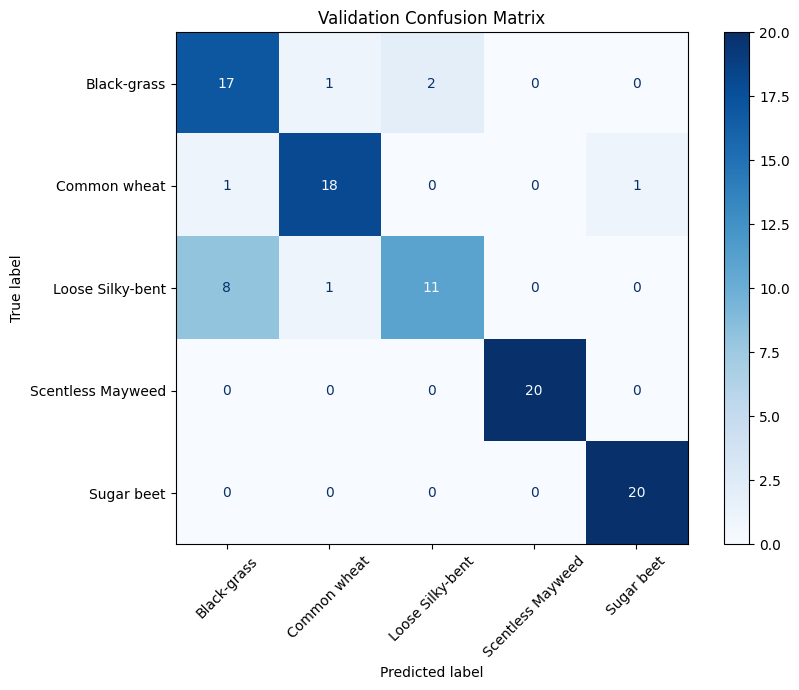

In [38]:
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. 加载最佳模型
# 如果 best_model.pth 保存的是 model.state_dict()
model.load_state_dict(
    torch.load("best_model.pth", map_location=device)
)
model.eval()

# 2. 获取验证集的真实标签和预测标签
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.tolist())

# 3. 查看每一类的分类表现
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 4. 绘制混淆矩阵
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

print(cm)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()